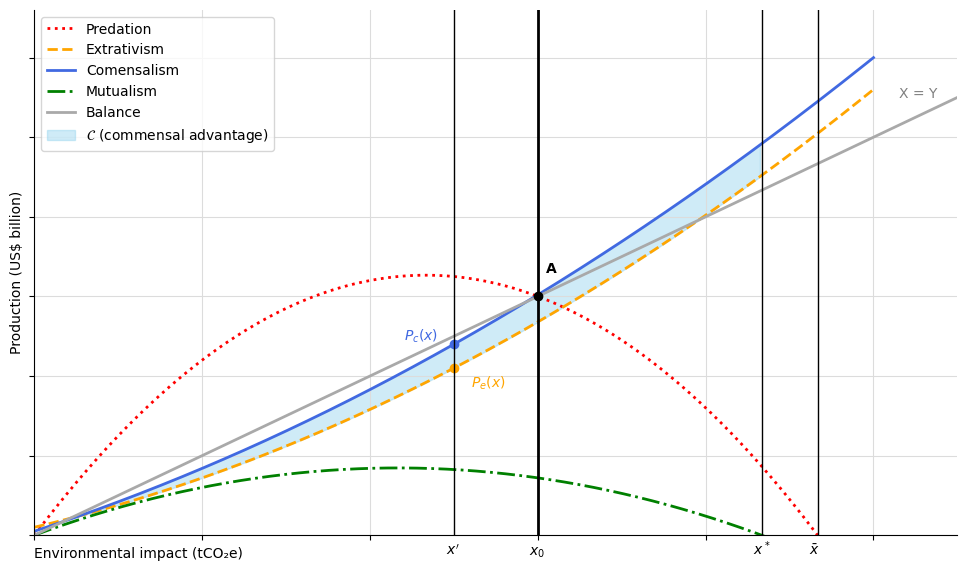

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Domínio de X (impacto ambiental)
x = np.linspace(0, 10, 400)

# Funções de produção
y_predatoria = 2.8 * x - 0.3 * x**2
y_comensal =  0.05 * x**2 + 0.69 * x + 0.10
y_extrativista = 0.06 * x**2 + 0.5 * x + 0.2
y_mutualista = 0.78 * x - 0.09 * x**2

# Equilíbrio x = y
x_equilibrio = np.linspace(0, x.max() * 1.1, 100)
y_equilibrio = x_equilibrio

# Cálculo dos pontos críticos
x_star = 0.78 / 0.09  # mutualista = 0
x_bar = 2.8 / 0.3     # predatória = 0
x_0 = 6.0             # interseção entre predatória e x=y
y_A = x_0             # valor em x=y

# Área da vantagem comensalista (𝓒)
mask = (x >= 0) & (x <= x_star)
x_fill = x[mask]
yc_fill = y_comensal[mask]
ye_fill = y_extrativista[mask]

# Gráfico único
fig, ax = plt.subplots(figsize=(10, 6))

# Curvas principais
ax.plot(x, y_predatoria, label='Predation', linestyle=':', linewidth=2, color='red')
ax.plot(x, y_extrativista, label='Extrativism', linestyle='--', linewidth=2, color='orange')
ax.plot(x, y_comensal, label='Comensalism', linestyle='-', linewidth=2, color='royalblue')
ax.plot(x, y_mutualista, label='Mutualism', linestyle='-.', linewidth=2, color='green')
ax.plot(x_equilibrio, y_equilibrio, label='Balance', linestyle='-', linewidth=2, color='darkgray')

# Sombreamento da área 𝓒
ax.fill_between(x_fill, ye_fill, yc_fill, where=ye_fill < yc_fill, interpolate=True,
                color='skyblue', alpha=0.4, label=r'$\mathcal{C}$ (commensal advantage)')

# Estética
ax.set_xlabel('Environmental impact (tCO₂e)', loc='left', labelpad=5)
ax.set_ylabel('Production (US$ billion)')
ax.set_ylim(0, max(y_predatoria.max(), y_comensal.max(), y_extrativista.max(), y_mutualista.max()) * 1.1)
ax.set_xlim(0, x.max() * 1.1)
fig.tight_layout()
ax.tick_params(axis='both', which='both', labelbottom=False, labelleft=False)
ax.grid(True, color='gainsboro')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Texto "X = Y"
ax.annotate('X = Y', xy=(10, 10.7), xytext=(10.3, 11), fontsize=10, color='gray')

# Legenda
ax.legend(loc='upper left')

# Pontos P_c(x) e P_e(x)
x_sample = 5
Pc_x = 0.06 * x_sample**2 + 0.5 * x_sample + 0.2
Pe_x = 0.05 * x_sample**2 + 0.69 * x_sample + 0.10
ax.plot(x_sample, Pc_x, 'o', color='orange')
ax.annotate(r'$P_e(x)$', xy=(x_sample, Pc_x), xytext=(x_sample + 0.2, Pc_x - 0.5), color='orange')
ax.plot(x_sample, Pe_x, 'o', color='royalblue')
ax.annotate(r'$P_c(x)$', xy=(x_sample, Pe_x), xytext=(x_sample - 0.6, Pe_x + 0.1), color='royalblue')

# Linhas verticais e ponto A
ax.axvline(x=x_sample, linestyle='-', color='black', linewidth=1)
ax.annotate(r"$x'$", xy=(x_sample, 0), xytext=(x_sample - 0.1, -0.5))
ax.axvline(x=x_star, linestyle='-', color='black', linewidth=1)
ax.annotate(r'$x^*$', xy=(x_star, 0), xytext=(x_star - 0.1, -0.5))
ax.axvline(x=x_bar, linestyle='-', color='black', linewidth=1)
ax.annotate(r'$\bar{x}$', xy=(x_bar, 0), xytext=(x_bar - 0.1, -0.5))
ax.axvline(x=x_0, linestyle='-', color='black', linewidth=2)
ax.annotate(r'$x_0$', xy=(x_0, 0), xytext=(x_0 - 0.1, -0.5))
ax.plot(x_0, y_A, 'ko')  # ponto A
ax.annotate('A', xy=(x_0, y_A), xytext=(x_0 + 0.1, y_A + 0.6),
            fontsize=10, weight='bold')

plt.show()
